# 02: DAS pipeline on Monterey Bay earthquakes

Takes a DAS earthquake waterfall and turns every good/working channel into the
format the EQ/UNE classifiers expect (0.5-10 Hz, 20 Hz, 1200 samples,
P at sample 200, peak-normalized).

This is the DAS half of the transfer test. The models are trained on
seismograms; our question is whether they still work when the input is a
fibre-optic cable channel.

**Before running:** `python scripts/download_monterey.py --limit 3`

In [29]:
import sys, os
sys.path.append("..") #so 'src' imports work from inside notebooks/

import numpy as np
import matplotlib.pyplot as plt

from src.das_io import load_das_event, select_channels, channel_snr
from src.preprocess import preprocess_trace, bandpass, pick_p
from src.features import extract_features, feature_table, RF_V2_FEATURES

## 1. Load one event

In [30]:
from pathlib import Path

DATA_DIR = Path("../data/monterey_bay/data")
files = sorted(DATA_DIR.glob("*.h5"))
print(f"{len(files)} event files found")

data, meta = load_das_event(files[0])

print(f"\nevent{meta.get('event_id')}")
print(f"time{meta.get('event_time')}")
print(f"magnitude M{meta.get('magnitude')} {meta.get('magnitude_type', '')}")
print(f"location {meta.get('latitude')}, {meta.get('longitude')}  depth {meta.get('depth_km')} km")
print(f"shape {meta['n_channels']} channels x {meta['n_time']} samples")
print(f"rate {meta['fs']} Hz channel spacing {meta.get('dx_m')} m")
print(f"units {meta.get('unit')}")
print(f"duration {meta['n_time'] / meta['fs']:.0f} s")

5 event files found

eventMBARI_GL20m_OCP5m_FS200Hz_2022-07-30T233258Z
time
magnitude MNone 
location None, None  depth None km
shape 2845 channels x 12000 samples
rate 200.00495922941204 Hz channel spacing 5.2 m
units microstrain/s
duration 60 s


In [31]:
import h5py
with h5py.File(files[0], "r") as f:
    for k, v in f["data"].attrs.items():
        print(f"{k:22s} {v}")
    print("\nother keys in file:", list(f.keys()))

begin_time             2022-07-30T23:32:58.000000+00:00
dt_s                   0.004999876022338867
dx_m                   5.2
end_time               2022-07-30T23:33:57.000000+00:00
event_id               MBARI_GL20m_OCP5m_FS200Hz_2022-07-30T233258Z
event_time             
event_time_index       -1
source                 monterey bay
unit                   microstrain/s

other keys in file: ['data']


peak STA/LTA: median 2.68, max 9.96
above 5: 19 of 569


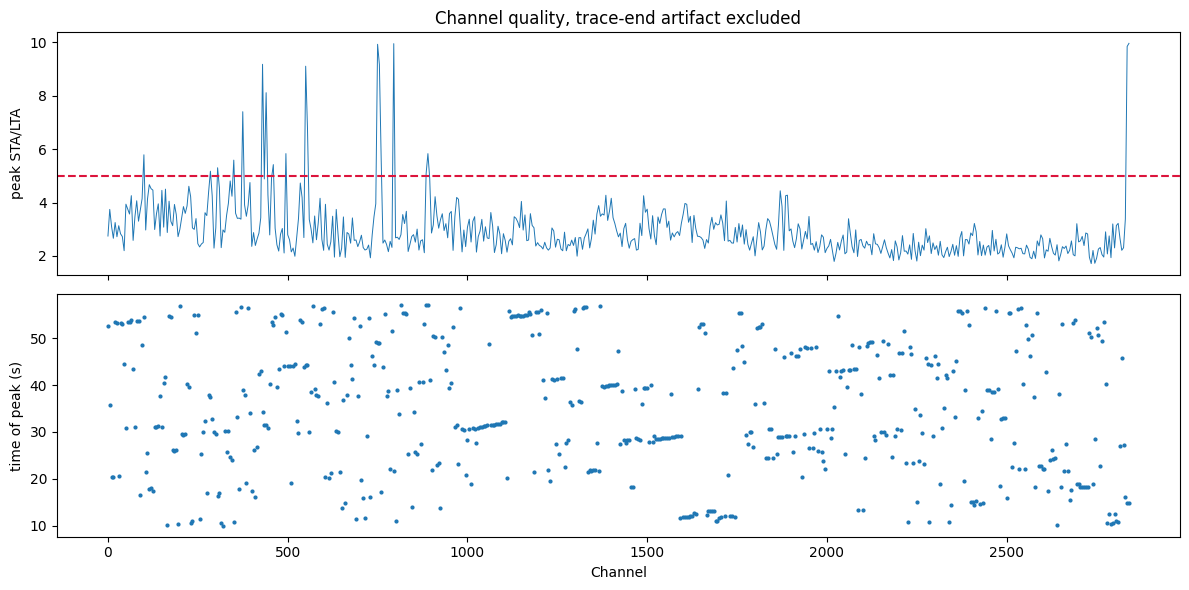

In [32]:
scores, picks, chans = [], [], []
for c in sub:
    x, fs2 = resample(bandpass(data[c], meta["fs"]), meta["fs"])
    e = x ** 2
    cs = np.cumsum(np.insert(e, 0, 0.0))
    nsta, nlta = 20, 200
    sta = (cs[nsta:] - cs[:-nsta]) / nsta
    lta = (cs[nlta:] - cs[:-nlta]) / nlta
    n = min(len(sta) - (nlta - nsta), len(lta))
    r = np.where(lta[:n] > 0, sta[nlta-nsta:nlta-nsta+n] / lta[:n], 0)

    r[-60:] = 0          # ignore the last 3 s: filter edge transient
    if r.max() == 0:
        continue
    scores.append(r.max()); picks.append((np.argmax(r) + nlta) / fs2); chans.append(c)

scores, picks = np.array(scores), np.array(picks)
print(f"peak STA/LTA: median {np.median(scores):.2f}, max {scores.max():.2f}")
print(f"above 5: {(scores > 5).sum()} of {len(scores)}")

fig, ax = plt.subplots(2, 1, figsize=(12, 6), sharex=True)
ax[0].plot(chans, scores, lw=0.7); ax[0].axhline(5, color="crimson", ls="--")
ax[0].set_ylabel("peak STA/LTA")
ax[1].scatter(chans, picks, s=4)
ax[1].set_xlabel("Channel"); ax[1].set_ylabel("time of peak (s)")
ax[0].set_title("Channel quality, trace-end artifact excluded")
plt.tight_layout(); plt.show()

## 2. Raw waterfall

Time down, distance along the cable across

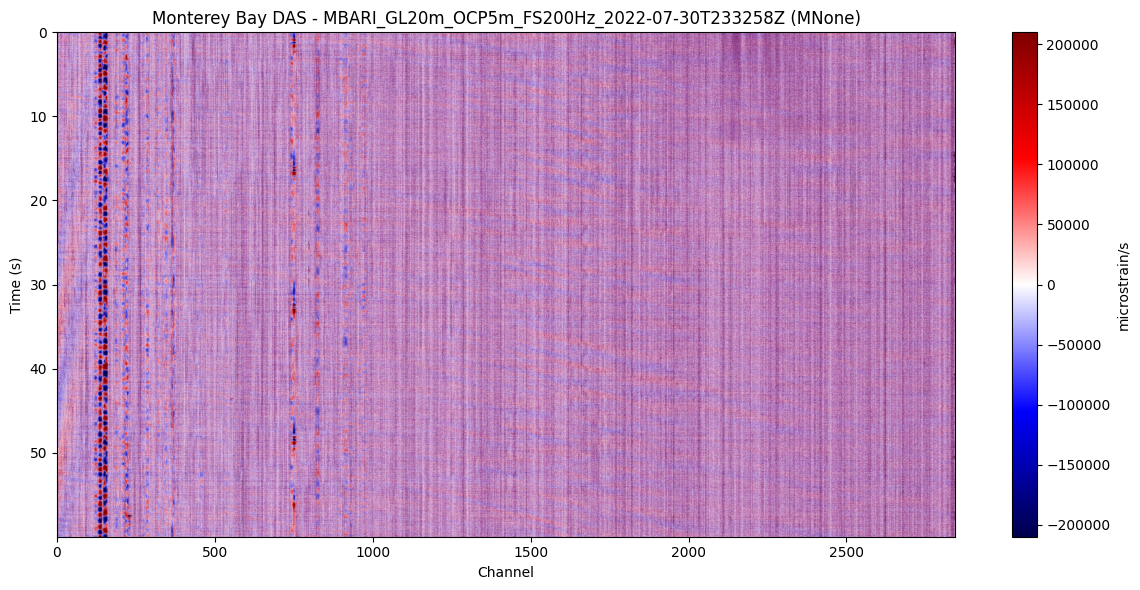

In [33]:
clip = np.percentile(np.abs(data), 98)

plt.figure(figsize=(12, 6))
plt.imshow(data.T, aspect="auto", cmap="seismic", vmin=-clip, vmax=clip,
           extent=[0, meta["n_channels"], meta["n_time"] / meta["fs"], 0])
plt.xlabel("Channel")
plt.ylabel("Time (s)")
plt.title(f"Monterey Bay DAS - {meta.get('event_id')} (M{meta.get('magnitude')})")
plt.colorbar(label=meta.get("unit", ""))
plt.tight_layout()
plt.show()

## 3. Picking the "good" channels

DAS gives thousands of channels and many are useless, like bad coupling to the
seafloor, local noise. Prof's handout's DAS test took 100 channels
per event chosen on SNR, so we tried doing the same.

`event_time_index` is the ORIGIN time, not the P arrival, so it is only a
lower bound for where the signal starts. We use it to split noise from signal
when scoring SNR.

kept 89 of 2845 channels (SNR >= 2.0)
SNR range: 2.0 to 3.4


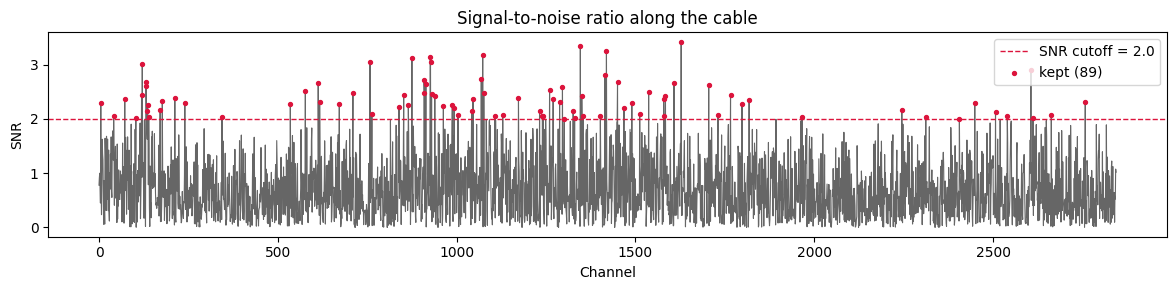

In [34]:
split= meta.get("event_time_index") or int(0.25 * meta["n_time"])
keep, snrs = select_channels(data, split_index=split, n=100, min_snr=2.0)

print(f"kept {len(keep)} of {meta['n_channels']} channels (SNR >= 2.0)")
if len(keep):
    print(f"SNR range: {snrs.min():.1f} to {snrs.max():.1f}")

plt.figure(figsize=(12, 3))
all_snr = np.array([channel_snr(tr, split) for tr in data])
plt.plot(all_snr, lw=0.8, color="0.4")
plt.axhline(2.0, color="crimson", ls="--", lw=1, label="SNR cutoff = 2.0")
plt.scatter(keep, snrs, s=8, color="crimson", zorder=3, label=f"kept ({len(keep)})")
plt.xlabel("Channel"); plt.ylabel("SNR"); plt.legend()
plt.title("Signal-to-noise ratio along the cable")
plt.tight_layout(); plt.show()

## 4. Before and after for one channel

Should show raw channel on top, processed 1200 sample
window below, with the P pick marked.

channel 133
  original_fs          200.00495922941204
  original_samples     12000
  resampled_samples    1200
  p_source             sta_lta
  p_index              200
  p_time_s             10.0


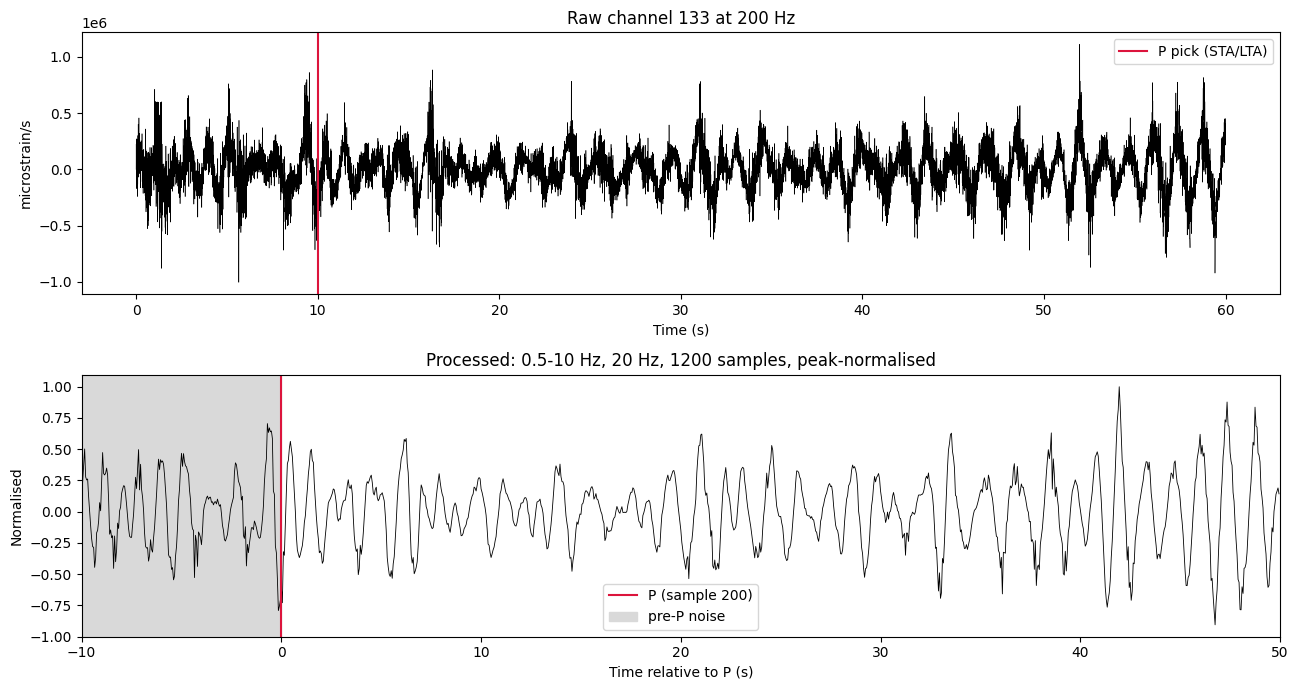

In [35]:
window = info = ch = None
for c in keep:
    try:
        window, info = preprocess_trace(data[int(c)], meta["fs"])
        ch = int(c)
        break
    except ValueError:
        continue
if window is None:
    raise RuntimeError("no channel yielded a full 60 s window")
raw = data[ch]

print(f"channel {ch}")
for k, v in info.items():
    print(f"  {k:20s} {v}")

fig, axes = plt.subplots(2, 1, figsize=(13, 7))

t_raw = np.arange(len(raw)) / meta["fs"]
axes[0].plot(t_raw, raw, "k-", lw=0.4)
axes[0].axvline(info["p_time_s"], color="crimson", lw=1.5, label="P pick (STA/LTA)")
axes[0].set_title(f"Raw channel {ch} at {meta['fs']:.0f} Hz")
axes[0].set_xlabel("Time (s)"); axes[0].set_ylabel(meta.get("unit", "")); axes[0].legend()

t_win = (np.arange(1200) - 200) / 20.0 # 0s = the P arrival
axes[1].plot(t_win, window, "k-", lw=0.6)
axes[1].axvline(0, color="crimson", lw=1.5, label="P (sample 200)")
axes[1].axvspan(-10, 0, color="0.85", label="pre-P noise")
axes[1].set_xlim(-10, 50)
axes[1].set_title("Processed: 0.5-10 Hz, 20 Hz, 1200 samples, peak-normalised")
axes[1].set_xlabel("Time relative to P (s)"); axes[1].set_ylabel("Normalised"); axes[1].legend()

plt.tight_layout(); plt.show()

## 5. Kept channels

Some channels will fail with no STA/LTA trigger, or from the 60s window running off
the end.

In [36]:
windows, infos, used, failures = [], [], [], {}

for c in keep:
    try:
        w, i = preprocess_trace(data[int(c)], meta["fs"])
        windows.append(w); infos.append(i); used.append(int(c))
    except ValueError as e:
        reason=str(e).split("(")[0].strip()[:45]
        failures[reason] = failures.get(reason, 0) + 1

print(f"processed {len(windows)} of {len(keep)} channels")
for reason, n in failures.items():
    print(f"  skipped {n:3d}: {reason}")

processed 2 of 89 channels
  skipped   1: window [42:1242] does not fit in a trace of 1
  skipped   1: window [229:1429] does not fit in a trace of 
  skipped   1: window [952:2152] does not fit in a trace of 
  skipped   1: window [428:1628] does not fit in a trace of 
  skipped   1: window [75:1275] does not fit in a trace of 1
  skipped   4: window [970:2170] does not fit in a trace of 
  skipped   1: window [110:1310] does not fit in a trace of 
  skipped   1: window [999:2199] does not fit in a trace of 
  skipped   1: window [135:1335] does not fit in a trace of 
  skipped   3: window [973:2173] does not fit in a trace of 
  skipped   2: window [957:2157] does not fit in a trace of 
  skipped   1: window [250:1450] does not fit in a trace of 
  skipped   3: window [959:2159] does not fit in a trace of 
  skipped   1: window [421:1621] does not fit in a trace of 
  skipped   1: window [118:1318] does not fit in a trace of 
  skipped   1: window [32:1232] does not fit in a trace of

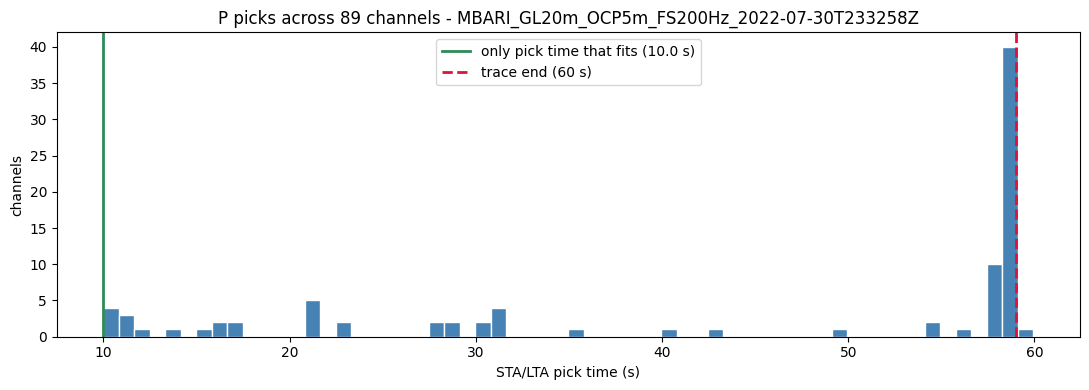

52 of 89 picks land in the last 5 s - almost certainly filter edge artifacts


In [37]:
import numpy as np, matplotlib.pyplot as plt
from src.preprocess import bandpass, resample, pick_p

picks = []
for c in keep:
    x, fs2 = resample(bandpass(data[int(c)], meta["fs"]), meta["fs"])
    p = pick_p(x, fs2)
    if p is not None:
        picks.append(p / fs2)

plt.figure(figsize=(11, 4))
plt.hist(picks, bins=60, color="steelblue", edgecolor="white")
plt.axvline(10, color="seagreen", lw=2, label="only pick time that fits (10.0 s)")
plt.axvline(59, color="crimson", ls="--", lw=2, label="trace end (60 s)")
plt.xlabel("STA/LTA pick time (s)"); plt.ylabel("channels")
plt.title(f"P picks across {len(picks)} channels - {meta.get('event_id')}")
plt.legend(); plt.tight_layout(); plt.show()

late = sum(p > 55 for p in picks)
print(f"{late} of {len(picks)} picks land in the last 5 s - almost certainly filter edge artifacts")

### Moveout check

If the picks are real, they should drift smoothly along the cable as the
wavefront travels, not jump around at random.

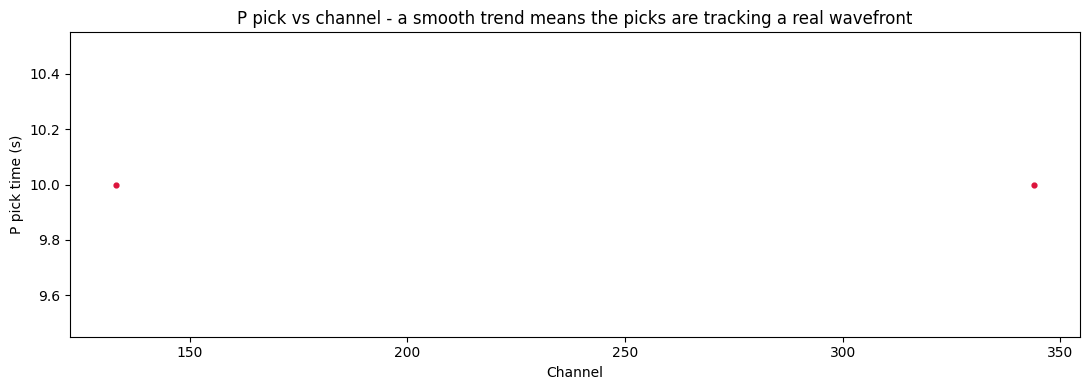

pick spread: 10.0 to 10.0 s  (std 0.00 s)


In [38]:
picks = np.array([i["p_time_s"] for i in infos])

plt.figure(figsize=(11, 4))
plt.scatter(used, picks, s=12, color="crimson")
plt.xlabel("Channel"); plt.ylabel("P pick time (s)")
plt.title("P pick vs channel - a smooth trend means the picks are tracking a real wavefront")
plt.tight_layout(); plt.show()

print(f"pick spread: {picks.min():.1f} to {picks.max():.1f} s  (std {picks.std():.2f} s)")

## 6. Features

The 13 RF-v2 features, one row per channel. This matrix is what gets fed
to the classifier.

In [39]:
X, names = feature_table(windows)
print(f"feature matrix: {X.shape[0]} channels x {X.shape[1]} features")

import pandas as pd
df = pd.DataFrame(X, columns=names, index=used)
df.index.name = "channel"
display(df.describe().T[["mean", "std", "min", "max"]].round(3))

feature matrix: 2 channels x 13 features


,mean,std,min,max
rms,0.211,0.106,0.136,0.286
peak,1.000,0.000,1.000,1.000
peak_rms_ratio,5.416,2.714,3.497,7.335
early_e,0.045,0.041,0.016,0.074
middle_e,0.034,0.012,0.025,0.042
late_e,0.061,0.058,0.020,0.103
dominant_frequency,0.742,0.012,0.733,0.750
spectral_centroid,2.684,0.331,2.449,2.918
bandwidth,2.701,0.105,2.627,2.776
crest_factor,5.416,2.714,3.497,7.335


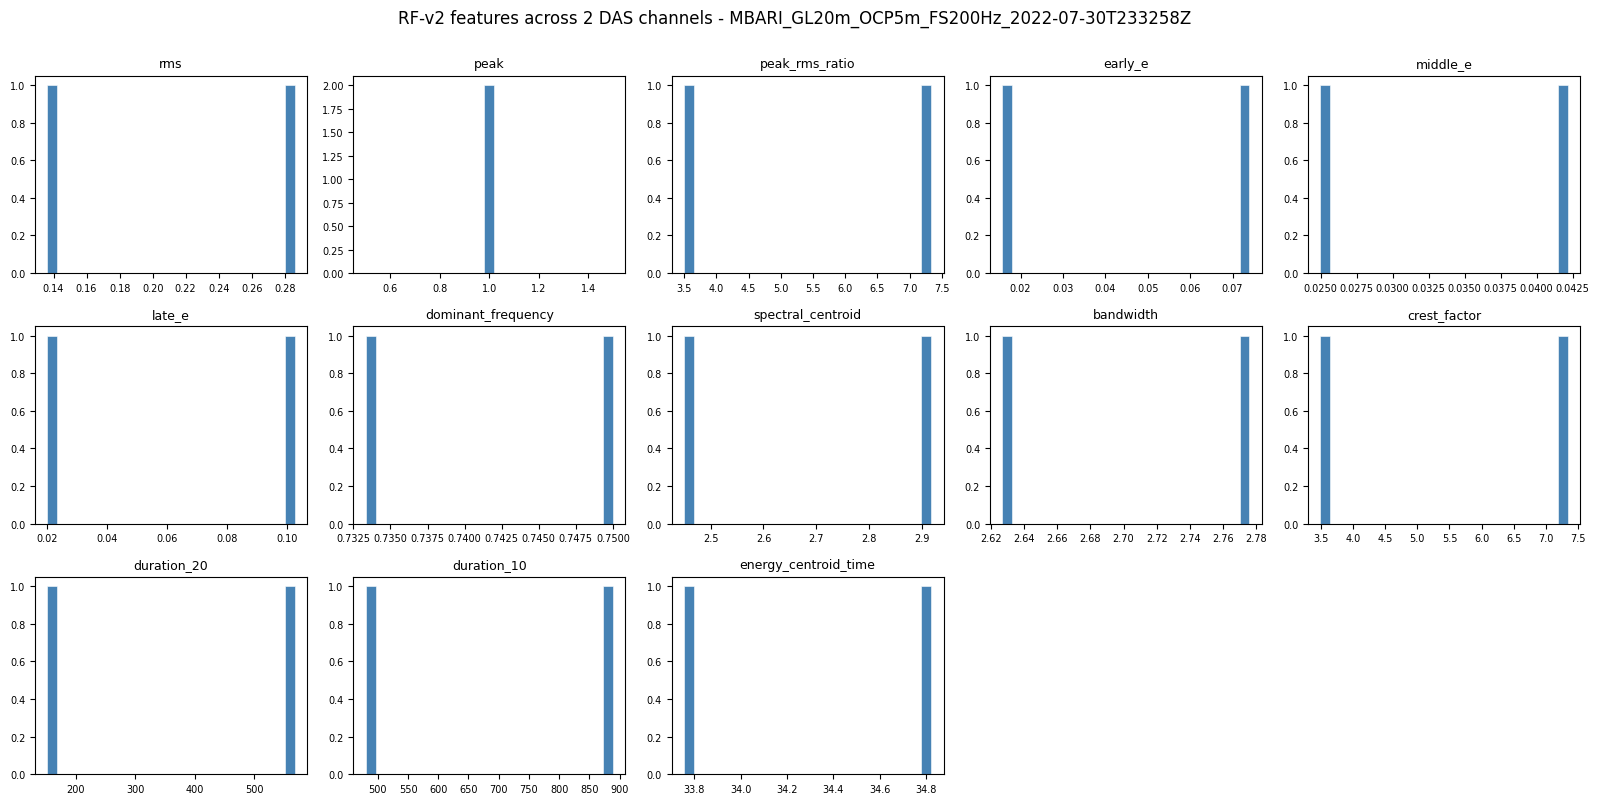

In [40]:
fig, axes = plt.subplots(3, 5, figsize=(16, 8))
for ax, name in zip(axes.ravel(), names):
    ax.hist(df[name], bins=25, color="steelblue", edgecolor="white", lw=0.4)
    ax.set_title(name, fontsize=9)
    ax.tick_params(labelsize=7)
for ax in axes.ravel()[len(names):]:
    ax.axis("off")
plt.suptitle(f"RF-v2 features across {len(df)} DAS channels - {meta.get('event_id')}", y=1.0)
plt.tight_layout(); plt.show()

## 7. Save

One CSV per event. Collect these across all 33 events and that is the DAS
earthquake corpus the classifier gets tested on.

In [41]:
out = Path("../data/features")
out.mkdir(exist_ok=True, parents=True)

df["event_id"] = meta.get("event_id")
df["magnitude"] = meta.get("magnitude")
df["depth_km"] = meta.get("depth_km")
df["latitude"] = meta.get("latitude")
df["longitude"] = meta.get("longitude")
df["label"] = "earthquake"

path = out / f"{meta.get('event_id', files[0].stem)}_features.csv"
df.to_csv(path)
print(f"wrote {path}  ({len(df)} rows)")

wrote ..\data\features\MBARI_GL20m_OCP5m_FS200Hz_2022-07-30T233258Z_features.csv  (2 rows)


In [42]:
for fp in sorted(DATA_DIR.glob("*.h5")):
    d, m = load_das_event(fp)
    best = 0
    for c in range(0, m["n_channels"], 25):
        x, f2 = resample(bandpass(d[c], m["fs"]), m["fs"])
        e = x ** 2; cs = np.cumsum(np.insert(e, 0, 0.0))
        sta = (cs[20:] - cs[:-20]) / 20; lta = (cs[200:] - cs[:-200]) / 200
        n = min(len(sta) - 180, len(lta))
        r = np.where(lta[:n] > 0, sta[180:180+n] / lta[:n], 0)
        r[-60:] = 0
        best = max(best, r.max())
    print(f"{fp.name}   best STA/LTA {best:5.1f}")

20220730T233258Z.h5   best STA/LTA   9.9
20220802T054858Z.h5   best STA/LTA   8.6
20220808T174058Z.h5   best STA/LTA   8.3
20220809T005458Z.h5   best STA/LTA   9.0
20220809T080958Z.h5   best STA/LTA   8.8


In [43]:
import numpy as np
from scipy.signal import butter, sosfiltfilt

fp = sorted(DATA_DIR.glob("*.h5"))[0]
d, m = load_das_event(fp)
fs = m["fs"]

def best_stalta(x, lo, hi, fs):
    x = np.asarray(x, float); x = x - x.mean()
    sos = butter(4, [lo, min(hi, 0.45 * fs)], btype="bandpass", fs=fs, output="sos")
    y = sosfiltfilt(sos, x)
    e = y ** 2; cs = np.cumsum(np.insert(e, 0, 0.0))
    nsta, nlta = int(0.5 * fs), int(5 * fs)
    sta = (cs[nsta:] - cs[:-nsta]) / nsta
    lta = (cs[nlta:] - cs[:-nlta]) / nlta
    n = min(len(sta) - (nlta - nsta), len(lta))
    r = np.where(lta[:n] > 0, sta[nlta-nsta:nlta-nsta+n] / lta[:n], 0)
    r[-int(3 * fs):] = 0
    return r.max()

for lo, hi in [(0.5, 10), (2, 20), (5, 40), (10, 60), (20, 80)]:
    best = max(best_stalta(d[c], lo, hi, fs) for c in range(0, m["n_channels"], 25))
    print(f"{lo:4.1f} - {hi:2.0f} Hz   best STA/LTA {best:6.1f}")

 0.5 - 10 Hz   best STA/LTA    9.8
 2.0 - 20 Hz   best STA/LTA    9.7
 5.0 - 40 Hz   best STA/LTA    9.7
10.0 - 60 Hz   best STA/LTA    9.4
20.0 - 80 Hz   best STA/LTA    9.1


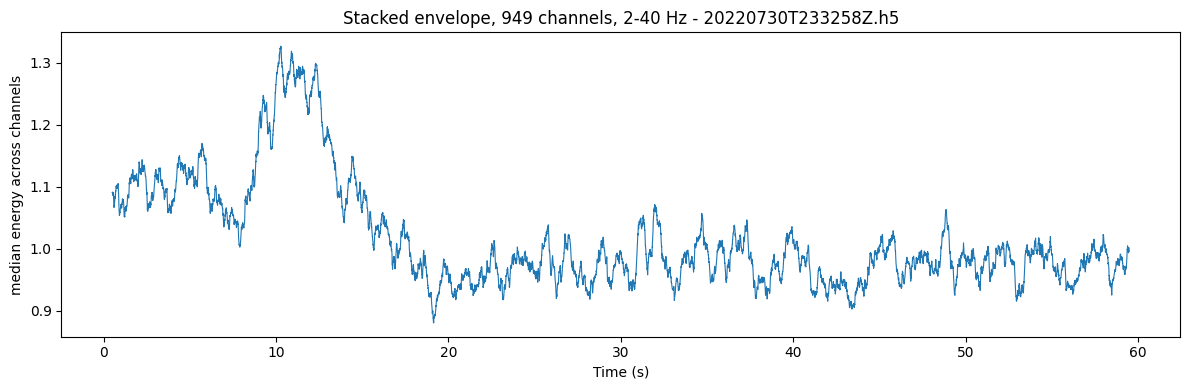

peak / baseline ratio: 1.3


In [ ]:
import matplotlib.pyplot as plt

sos = butter(4, [2, 40], btype="bandpass", fs=fs, output="sos")
env = []
for c in range(0, m["n_channels"], 3):
    y = sosfiltfilt(sos, d[c] - d[c].mean())
    env.append(y ** 2 / np.median(y ** 2))      # normalise so loud channels don't dominate
env = np.array(env)

med = np.median(env, axis=0)
w = int(0.5 * fs)
smooth = np.convolve(med, np.ones(w) / w, mode="same")
t = np.arange(len(smooth)) / fs

plt.figure(figsize=(12, 4))
plt.plot(t[w:-w], smooth[w:-w], lw=0.8)
plt.xlabel("Time (s)"); plt.ylabel("median energy across channels")
plt.title(f"Stacked envelope, {env.shape[0]} channels, 2-40 Hz - {fp.name}")
plt.tight_layout()
plt.savefig("../assets/stacked_envelope.png", dpi=150, bbox_inches="tight")
plt.show()

print(f"peak / baseline ratio: {smooth[w:-w].max() / np.median(smooth[w:-w]):.1f}")

In [46]:
P_SECONDS = 10.0
p_raw = int(round(P_SECONDS * meta["fs"]))     # ~2000 at 200 Hz

windows, used, failures = [], [], {}
for c in range(0, meta["n_channels"], 3):
    try:
        w, i = preprocess_trace(data[c], meta["fs"], p_index=p_raw)
        windows.append(w); used.append(c)
    except ValueError as e:
        r = str(e).split("(")[0].strip()[:45]
        failures[r] = failures.get(r, 0) + 1

print(f"processed {len(windows)} of {len(range(0, meta['n_channels'], 3))} channels")
for r, n in failures.items():
    print(f"  skipped {n}: {r}")

X, names = feature_table(windows)
print(f"\nfeature matrix: {X.shape}")

processed 949 of 949 channels

feature matrix: (949, 13)


In [ ]:
import pandas as pd
from pathlib import Path

out = Path("../data/features"); out.mkdir(parents=True, exist_ok=True)
total = 0

for fp2 in sorted(DATA_DIR.glob("*.h5")):
    d2, m2 = load_das_event(fp2)
    p_raw2 = int(round(10.0 * m2["fs"]))
    wins, chans = [], []
    for c in range(0, m2["n_channels"], 3):
        try:
            w2, _ = preprocess_trace(d2[c], m2["fs"], p_index=p_raw2)
            wins.append(w2); chans.append(c)
        except ValueError:
            pass
    if not wins:
        print(f"{fp2.name}: no channels"); continue
    X2, names2 = feature_table(wins)
    df2 = pd.DataFrame(X2, columns=names2, index=chans)
    df2.index.name = "channel"
    df2["event_file"] = fp2.name
    df2["label"] = "earthquake"
    df2.to_csv(out / f"{fp2.stem}_features.csv")
    total += len(df2)
    print(f"{fp2.name}: {len(df2)} channels")

print(f"\ntotal rows: {total}")